# Lineární pružnost metodou konečných prvků v Pythonu

Hodina krok za krokem prochází **kapitolu 6 učebního textu** S. Sysaly
a ke každému kroku ukazuje, jak ho v Pythonu udělat jednoduše a efektivně.
Značení i pořadí výkladu odpovídá textu a všechny použité vzorce jsou
vypsány přímo zde (čísla v závorkách jsou čísla rovnic v učebním textu).
Před každou buňkou s kódem je vysvětleno, co a proč počítáme.

| Čas | Část | Učební text |
|---|---|---|
| 0–5 | 1. Modelová úloha | 3.3 |
| 5–10 | 2. Od slabé formulace k soustavě $Ky=b$ | 4, 5, 6.1 |
| 10–20 | 3. Triangulace v Gmsh: `coord`, `elem`, $\Gamma_0$ | 6.1, 6.5 |
| 20–30 | 4. Referenční prvek, bazické funkce | 6.2 |
| 30–36 | 5. Izoparametrická transformace | 6.3 |
| 36–42 | 6. Numerická integrace | 6.4 |
| 42–46 | 7. Globální bazické funkce, množina $I_D$ | 6.6 |
| 46–62 | 8. Matice tuhosti $\tilde K=B^\top D_{\rm elast}B$ | 6.7 |
| 62–66 | 9. Vektor objemových sil | 6.8 |
| 66–72 | 10. Okrajová podmínka a řešení | 6.6, 5 |
| 72–80 | 11. Výměna prvku P1 → Q1, konvergence | 6.2 |
| 80–90 | 12. Deska s otvorem, uzly druhého řádu | 6.1, 6.3 |
| bonus | 13. Sítě ve 3D: čtyřstěny a šestistěny | |

**Hlavní myšlenka implementace.** Python nepotřebuje cyklus přes prvky.
Všechny prvky a kvadraturní body zpracujeme najednou poli NumPy
a globální matice vyskládáme jako řídké matice SciPy.

Notebook obsahuje jen kód potřebný k výpočtu. Ilustrační obrázky vyrábí
doprovodný skript `prednaska_obrazky.py` (složka `obrazky_prednaska/`);
z něj importujeme i tři kreslicí funkce pro sítě a výsledky.
Potřebné balíky: `numpy`, `scipy`, `sympy`, `matplotlib` a `gmsh` (`pip install gmsh`).

In [1]:
import time                                   # měření času vyskládání

import gmsh                                   # síťovač (pip install gmsh)
import matplotlib.pyplot as plt               # grafy
import numpy as np                            # pole a lineární algebra
import sympy as sp                            # symbolické bazické funkce a jejich derivace
from scipy import sparse                      # řídké matice
from scipy.sparse.linalg import spsolve       # řídký přímý řešič soustavy K y = b

# kreslicí funkce z doprovodného skriptu: síť, deformovaný tvar, graf konvergence
from prednaska_obrazky import graf_konvergence, kresli, kresli_sit

## 1. Modelová úloha (sekce 3.3)

Řešíme úlohu **rovinné deformace** (3.30). Hledáme pole posunů
$u=(u_1,u_2)$, pole malých deformací a pole napětí

$$\varepsilon(u)=\tfrac12\bigl(\nabla u+(\nabla u)^\top\bigr),\qquad
\sigma=C\varepsilon=\lambda(\operatorname{tr}\varepsilon)I+2\mu\varepsilon$$

taková, že

$$\operatorname{div}\sigma+F=0 \text{ v } \Omega,\qquad
\sigma n=f \text{ na } \Gamma_1,\qquad u=0 \text{ na } \Gamma_0, \qquad (3.30)$$

kde $n$ je vnější jednotková normála a $\partial\Omega=\Gamma_0\cup\Gamma_1$.
Po celou hodinu používáme jednu modelovou úlohu:

* $\Omega=(0,4)\times(0,1)$, homogenní izotropní materiál $\lambda=\mu=1$,
* $\Gamma_0=\{0\}\times(0,1)$: těleso je zde pevně uchyceno, $u=0$,
* na $\Gamma_1$ (zbytek hranice) nulové povrchové síly $f=0$
  (stejně jako v sekcích 6.5–6.8 povrchové síly neuvažujeme),
* konstantní objemová síla (tíha) $F=(0,-10^{-3})$.

![modelová úloha](obrazky_prednaska/01_uloha.png)

In [2]:
lam, mu = 1.0, 1.0              # Laméovy koeficienty lambda, mu
F = np.array([0.0, -1e-3])      # konstantní objemová síla F = (F_1, F_2)

## 2. Od slabé formulace k soustavě $Ky=b$ (kapitoly 4, 5 a sekce 6.1)

**Slabá formulace.** Prostor přípustných posunů je
$V=\{v\in[W^{1,2}(\Omega)]^2\mid v=0\text{ na }\Gamma_0\}$ a hledáme

$$u\in V:\quad a(u,v)=L(v)\quad\forall v\in V, \qquad (4.15)$$

$$a(u,v)=\int_\Omega C\varepsilon(u):\varepsilon(v)\,dx \quad (4.13),\qquad
L(v)=\int_\Omega F\cdot v\,dx+\int_{\Gamma_1} f\cdot v\,ds, \quad (4.14)$$

kde $A:B=\sum_{i,j}A_{ij}B_{ij}$. Forma $a$ je symetrická a $V$-eliptická,
takže úloha má právě jedno řešení (Laxovo–Milgramovo lemma). Ekvivalentně
$u$ minimalizuje celkovou potenciální energii

$$J(v)=\tfrac12a(v,v)-L(v),\qquad v\in V. \qquad (4.18)$$

**Ritzova metoda** (kapitola 5): $V$ nahradíme prostorem konečné dimenze
$V_h=\operatorname{lin}\{\varphi_1,\dots,\varphi_n\}$ a formy $a$, $L$
jejich aproximacemi $a_h$, $L_h$ (numerická integrace). Pro
$v_h=y_1\varphi_1+\dots+y_n\varphi_n$ je

$$J_h(v_h)=\tfrac12y^\top Ky-b^\top y,\qquad K_{ij}=a_h(\varphi_i,\varphi_j),\quad
b_i=L_h(\varphi_i),$$

a minimum nastane právě pro řešení soustavy $Ky=b$.
$K$ je **matice tuhosti** a $b$ **vektor vnějších sil**.

**Metoda konečných prvků** (sekce 6.1) je Ritzova metoda se speciální bází
s malými nosiči (proto je $K$ řídká). Bázi konstruujeme ve třech krocích:

1. **triangulace** $\mathcal T_h$ oblasti $\Omega_h$ (trojúhelníky nebo čtyřúhelníky),
2. **lokální bazické funkce** $\varphi_{T,1},\dots,\varphi_{T,n_p}$ na každém prvku $T$
   pomocí referenčního prvku a transformace,
3. **globální bazické funkce** $\varphi_1,\dots,\varphi_{n_n}$ „slepením“ lokálních.

## 3. Krok 1: triangulace v Gmsh (sekce 6.1 a 6.5)

Triangulace $\mathcal T_h$ je množina prvků $T$ (trojúhelníků nebo čtyřúhelníků) taková, že

* a) $\Omega_h=\bigcup_{T\in\mathcal T_h}T$,
* b) $\operatorname{int}T\cap\operatorname{int}T'=\emptyset$ pro $T\neq T'$,
* c) hrana prvku $T$ je buď hranou jiného prvku $T'$, nebo částí $\partial\Omega_h$.

Pokud $\Omega$ není mnohoúhelník, pokrýváme jeho polygonální aproximaci $\Omega_h$.
V praxi se triangulaci říká **síť** a uzlovým bodům **uzly**; oba výrazy dále používáme.
Podle sekce 6.5 potřebujeme z triangulace:

* **pole souřadnic** `coord[j] = (x1, x2)` uzlu $N_j$, $j=1,\dots,n_n$,
* **pole elementů** `elem[T] = (j1, ..., j_np)`: čísla uzlů $N_{T,1},\dots,N_{T,n_p}$ prvku $T$,
* **uzly na Dirichletově části hranice** $\Gamma_{0,h}$.

**Indexování.** Text čísluje od 1, Python od 0: uzel $N_j$ má v poli index `j-1`.

Na malé triangulaci obdélníku $(0,2)\times(0,1)$ se čtyřmi trojúhelníky: řádek $j$ pole
`coord` jsou souřadnice uzlu $j$, řádek $T$ pole `elem` jsou globální čísla uzlů
$N_{T,1},N_{T,2},N_{T,3}$ prvku $T$. Například prvek $T=1$ má řádek `[0, 4, 3]`, tj.
$N_{1,1}=[0,0]$, $N_{1,2}=[1,1]$, $N_{1,3}=[0,1]$ – vrcholy jdou proti směru hodinových ručiček
jako na referenčním trojúhelníku. Uzel $4$ sdílejí prvky $0,1,3$, a proto se v `elem` opakuje.

![coord a elem](obrazky_prednaska/01b_coord_elem.png)

Sítě vytváříme v [Gmsh](https://gmsh.info), volně dostupném síťovači
s rozhraním pro Python. Postup je vždy stejný:

1. **geometrie** (jádro OpenCASCADE: obdélníky, kruhy, množinové operace),
2. **fyzikální skupiny** – pojmenované části hranice a oblasti, např. $\Gamma_0$,
   abychom jejich uzly našli i po vygenerování sítě,
3. **parametry sítě** (velikost prvků, trojúhelníky nebo čtyřúhelníky) a `generate`,
4. **převod** na naše pole `coord`, `elem` a indexy uzlů na $\Gamma_0$.

Gmsh čísluje uzly přirozenými čísly $1,2,\dots,n_n$ („tagy“), ale souřadnice nevrací
v tomto pořadí. Při převodu je proto seřadíme podle čísel uzlů (`np.argsort`)
a od čísel uzlů v prvcích odečteme 1, protože Python indexuje od nuly.
Síť lze uložit (`gmsh.write("sit.msh")`) nebo si ji prohlédnout v okně
Gmsh (`gmsh.fltk.run()`).

Následují čtyři krátké skripty, pro každou variantu sítě obdélníku $\Omega=(0,4)\times(0,1)$
jeden, seřazené od nejjednoduššího. Všechny mají stejné čtyři kroky a liší se jen v kroku 3
(a v typu prvků, které v kroku 4 čteme).

**Varianta 1: nestrukturovaná síť trojúhelníků.** Nejjednodušší případ: v kroku 3 zadáme
jen největší dovolenou velikost prvku `h` a rozmístění uzlů i trojúhelníků zvolí Gmsh sám.
Funkce `addRectangle` očísluje hrany obdélníku: 1 dolní, 2 pravá, 3 horní, 4 levá;
levá hrana je $\Gamma_0$.

In [3]:
gmsh.initialize()                                     # spustí jádro Gmsh (jednou na začátku práce)
gmsh.option.setNumber("General.Terminal", 0)          # 0 = Gmsh nevypisuje průběh do konzole

# 1. GEOMETRIE
# addRectangle(x, y, z, šířka, výška) vytvoří v jádře OpenCASCADE (occ) obdélník s levým
# dolním rohem [x, y, z]. Gmsh mu automaticky očísluje body, hrany (křivky) a plochu:
# plocha má číslo 1, hrany 1 = dolní, 2 = pravá, 3 = horní, 4 = levá.
gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
# OpenCASCADE drží geometrii zvlášť; synchronize ji předá do modelu Gmsh. Bez toho by
# následující příkazy (skupiny, síť) obdélník neviděly.
gmsh.model.occ.synchronize()

# 2. FYZIKÁLNÍ SKUPINA
# addPhysicalGroup(dimenze, [čísla entit], tag, name): pojmenovaná množina entit dané dimenze.
# Dimenze 1 = křivky, hrana 4 = levá hrana x1 = 0, tedy Gamma_0. Skupina dostane číslo 1
# a podle něj se po vygenerování sítě zeptáme na její uzly (krok 4).
gmsh.model.addPhysicalGroup(1, [4], tag=1, name="Gamma0")

# 3. PARAMETRY SÍTĚ A GENEROVÁNÍ
# Globální volba "Mesh.MeshSizeMax" = největší dovolená délka hrany prvku.
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.5)
# generate(2) vytvoří síť až do dimenze 2: nejprve uzly na hranách, pak trojúhelníky v ploše.
gmsh.model.mesh.generate(2)

# 4. PŘEVOD NA coord, elem A UZLY NA Gamma0
# getNodes() vrátí čísla (tagy) všech uzlů 1, ..., n_n a jejich souřadnice x, y, z za sebou;
# pořadí uzlů ve výstupu není podle čísel, proto souřadnice seřadíme podle tagů.
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord_n = xyz.reshape(-1, 3)[np.argsort(tagy), :2]        # řádek j = [x1, x2] uzlu j (z vynecháme)
# getElementsByType(typ) vrátí čísla prvků a čísla jejich uzlů za sebou;
# typ 2 = trojúhelník se 3 uzly. Odečtením 1 dostaneme indexy do coord (Python čísluje od 0).
_, uzly = gmsh.model.mesh.getElementsByType(2)
elem_n = uzly.reshape(-1, 3).astype(int) - 1              # řádek T = N_T,1, N_T,2, N_T,3
# getNodesForPhysicalGroup(dimenze, tag skupiny) vrátí čísla uzlů ležících na skupině 1 (Gamma0).
uzly_g0, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, 1)
gamma0_n = uzly_g0.astype(int) - 1

print("coord: tvar", coord_n.shape, " první řádky:\n", coord_n[:4])
print("elem: tvar", elem_n.shape, " první řádky:\n", elem_n[:4])
print("uzly na Gamma0:", gamma0_n)

coord: tvar (48, 2)  první řádky:
 [[0.         0.        ]
 [0.         1.        ]
 [0.         0.66666667]
 [0.         0.33333333]]
elem: tvar (68, 3)  první řádky:
 [[42 43 33]
 [33 43 30]
 [39 40 32]
 [28 39 32]]
uzly na Gamma0: [0 1 2 3]


Číslování si vždy nakreslíme: uzly (modře), prvky (červeně), u prvního prvku
i lokální čísla $1,2,3$ a uzly na $\Gamma_0$. Gmsh čísluje nejprve rohy,
pak uzly na hranách a nakonec vnitřní uzly. Proč musí lokální čísla jít
proti směru hodinových ručiček, uvidíme v části 5.

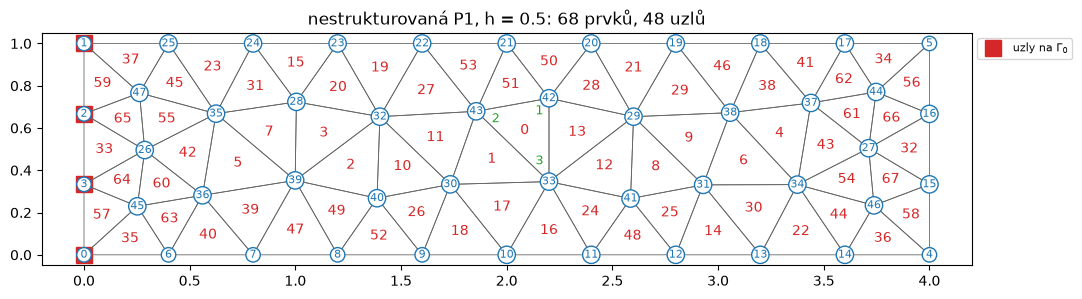

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.4))
kresli_sit(ax, coord_n, elem_n, gamma0_n)
ax.set_title(f"nestrukturovaná P1, h = 0.5: {len(elem_n)} prvků, {len(coord_n)} uzlů")
plt.show()

**Varianta 2: nestrukturovaná síť čtyřúhelníků.**

**Proč je potřeba `setRecombine`?** Síťovací algoritmy Gmsh ve 2D vytvářejí vždy
trojúhelníky. Čtyřúhelníky vzniknou až dodatečným krokem **rekombinace**: Gmsh spojí
dvojice sousedních trojúhelníků do čtyřúhelníků (výchozí algoritmus párování se snaží,
aby nezůstal žádný trojúhelník). `setRecombine(2, 1)` tento krok zapne pro plochu 1
(dimenze 2). Skript je jinak stejný jako varianta 1; v kroku 4 čteme prvky typu 3
(čtyřúhelník se 4 uzly). `gmsh.clear()` na začátku smaže předchozí model.

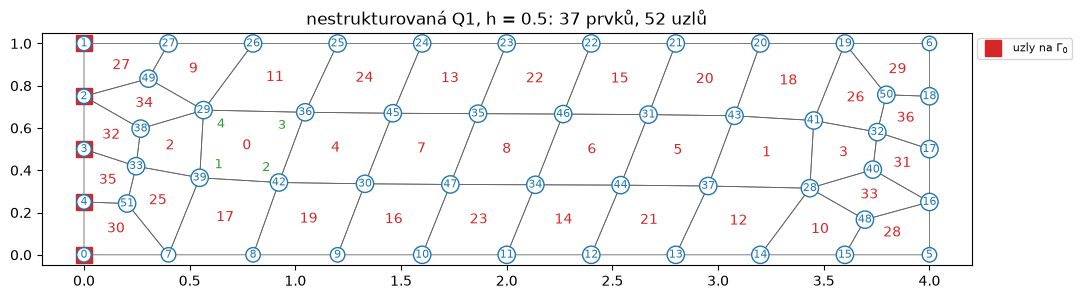

In [5]:
gmsh.clear()                                              # smaže předchozí geometrii i síť

# 1. geometrie: stejný obdélník (plocha 1, hrany 1-4) a předání do modelu
gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
gmsh.model.occ.synchronize()

# 2. fyzikální skupina Gamma0 = levá hrana 4
gmsh.model.addPhysicalGroup(1, [4], tag=1, name="Gamma0")

# 3. nestrukturovaná síť s velikostí prvku 0.5 ...
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.5)
# ... a setRecombine(dimenze 2, plocha 1): vzniklé trojúhelníky spojit do čtyřúhelníků
gmsh.model.mesh.setRecombine(2, 1)
gmsh.model.mesh.generate(2)

# 4. převod; prvky jsou nyní typu 3 = čtyřúhelník se 4 uzly
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord_nq = xyz.reshape(-1, 3)[np.argsort(tagy), :2]       # souřadnice seřazené podle čísla uzlu
_, uzly = gmsh.model.mesh.getElementsByType(3)
elem_nq = uzly.reshape(-1, 4).astype(int) - 1             # řádek T = N_T,1, ..., N_T,4
uzly_g0, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, 1)   # uzly skupiny 1 = Gamma0
gamma0_nq = uzly_g0.astype(int) - 1

fig, ax = plt.subplots(figsize=(12, 3.4))
kresli_sit(ax, coord_nq, elem_nq, gamma0_nq)
ax.set_title(f"nestrukturovaná Q1, h = 0.5: {len(elem_nq)} prvků, {len(coord_nq)} uzlů")
plt.show()

**Varianta 3: strukturovaná síť trojúhelníků 4 × 1.** Místo velikosti prvku předepíšeme
na každé hraně počet uzlů (`setTransfiniteCurve`) a plochu označíme jako strukturovanou
(`setTransfiniteSurface`). Uzly pak leží v pravidelné mřížce a Gmsh každý obdélníček
rozdělí úhlopříčkou na dva trojúhelníky. Tuto malou síť použijeme v dalších částech.

coord =
 [[0. 0.]
 [0. 1.]
 [4. 0.]
 [4. 1.]
 [1. 0.]
 [2. 0.]
 [3. 0.]
 [3. 1.]
 [2. 1.]
 [1. 1.]]
elem =
 [[0 4 1]
 [1 4 9]
 [4 5 9]
 [9 5 8]
 [5 6 8]
 [8 6 7]
 [6 2 7]
 [7 2 3]]
uzly na Gamma0: [0 1]


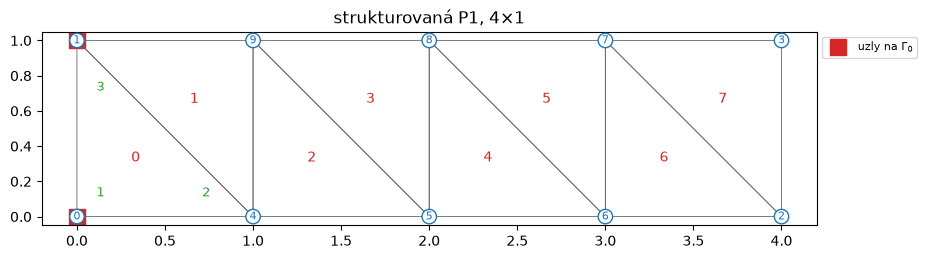

In [6]:
gmsh.clear()                                              # smaže předchozí geometrii i síť

# 1. geometrie
gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
gmsh.model.occ.synchronize()

# 2. fyzikální skupina Gamma0 = levá hrana 4
gmsh.model.addPhysicalGroup(1, [4], tag=1, name="Gamma0")

# 3. STRUKTUROVANÁ SÍŤ
# setTransfiniteCurve(hrana, počet uzlů): hrana se rozdělí rovnoměrně na (počet - 1) dílků.
# Vodorovné hrany 1 a 3 dostanou 5 uzlů (4 dílky), svislé hrany 2 a 4 dva uzly (1 dílek).
gmsh.model.mesh.setTransfiniteCurve(1, 5)
gmsh.model.mesh.setTransfiniteCurve(2, 2)
gmsh.model.mesh.setTransfiniteCurve(3, 5)
gmsh.model.mesh.setTransfiniteCurve(4, 2)
# setTransfiniteSurface(plocha): uzly uvnitř plochy 1 se umístí do pravidelné mřížky
# navazující na uzly na hranách -> strukturovaná síť
gmsh.model.mesh.setTransfiniteSurface(1)
gmsh.model.mesh.generate(2)

# 4. převod (typ 2 = trojúhelník se 3 uzly)
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord = xyz.reshape(-1, 3)[np.argsort(tagy), :2]
_, uzly = gmsh.model.mesh.getElementsByType(2)
elem = uzly.reshape(-1, 3).astype(int) - 1
uzly_g0, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, 1)
gamma0 = uzly_g0.astype(int) - 1

print("coord =\n", coord)
print("elem =\n", elem)
print("uzly na Gamma0:", gamma0)

fig, ax = plt.subplots(figsize=(10, 2.6))
kresli_sit(ax, coord, elem, gamma0)
ax.set_title("strukturovaná P1, 4×1")
plt.show()

**Varianta 4: strukturovaná síť čtyřúhelníků 4 × 1.** Varianta 3 a navíc rekombinace
(`setRecombine`). I strukturovaná síť je pro Gmsh nejprve síť trojúhelníků, takže bez
rekombinace bychom čtyřúhelníky nedostali. Na pravidelné mřížce rekombinace spojí právě
obě poloviny každého obdélníčku, takže vzniknou přesně obdélníky.

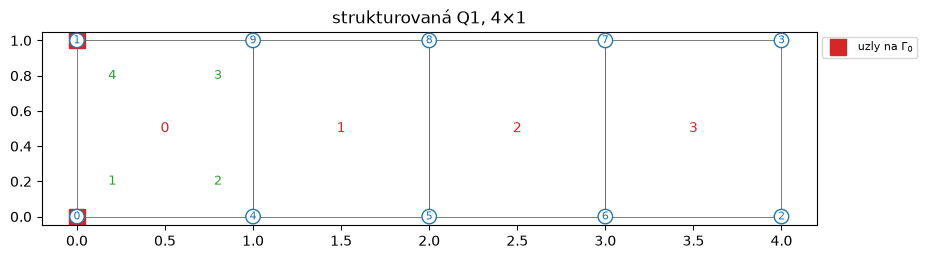

In [7]:
gmsh.clear()                                              # smaže předchozí geometrii i síť

# 1. geometrie
gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
gmsh.model.occ.synchronize()

# 2. fyzikální skupina Gamma0 = levá hrana 4
gmsh.model.addPhysicalGroup(1, [4], tag=1, name="Gamma0")

# 3. strukturovaná síť 4 x 1 jako ve variantě 3 ...
gmsh.model.mesh.setTransfiniteCurve(1, 5)
gmsh.model.mesh.setTransfiniteCurve(2, 2)
gmsh.model.mesh.setTransfiniteCurve(3, 5)
gmsh.model.mesh.setTransfiniteCurve(4, 2)
gmsh.model.mesh.setTransfiniteSurface(1)
# ... a spojení trojúhelníků do čtyřúhelníků (jako ve variantě 2)
gmsh.model.mesh.setRecombine(2, 1)
gmsh.model.mesh.generate(2)

# 4. převod (typ 3 = čtyřúhelník se 4 uzly)
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord_Q1 = xyz.reshape(-1, 3)[np.argsort(tagy), :2]
_, uzly = gmsh.model.mesh.getElementsByType(3)
elem_Q1 = uzly.reshape(-1, 4).astype(int) - 1
uzly_g0, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, 1)
gamma0_Q1 = uzly_g0.astype(int) - 1

fig, ax = plt.subplots(figsize=(10, 2.6))
kresli_sit(ax, coord_Q1, elem_Q1, gamma0_Q1)
ax.set_title("strukturovaná Q1, 4×1")
plt.show()

## 4. Krok 2: referenční konečný prvek Lagrangeova typu (sekce 6.2)

Referenční prvek je trojice $(\hat T,\hat S,\hat\Sigma)$:

* $\hat T$ je konvexní mnohoúhelník (trojúhelník nebo čtverec),
* $\hat S=\operatorname{lin}\{\hat\varphi_1,\dots,\hat\varphi_{n_p}\}$ je prostor polynomů dimenze $n_p$,
* $\hat\Sigma=\{\hat N_1,\dots,\hat N_{n_p}\}\subset\hat T$ jsou uzlové body takové, že

$$\hat\varphi_p(\hat N_q)=\delta_{pq}=\begin{cases}1,&p=q,\\0,&p\neq q,\end{cases}
\qquad\forall p,q\in\{1,\dots,n_p\}. \qquad (6.1)$$

Učební text uvádí čtyři prvky (obrázky 6.2–6.5). **Pořadí uzlů je součástí
definice prvku** a stejné pořadí budeme dodržovat na každém prvku sítě.

![referenční prvky](obrazky_prednaska/02_referencni_prvky.png)

### Odvození bazických funkcí z parametrického předpisu

Bazické funkce nemusíme znát předem. Stačí znát prostor $\hat S$ zadaný
**parametrickým předpisem**, tj. obecnou funkcí s $n_p$ neznámými koeficienty,
a uzly $\hat N_1,\dots,\hat N_{n_p}$. Pro P1 je $\hat S=P_1(\hat T)$ (polynomy 1. stupně) a

$$\hat\varphi(\xi)=a+b\,\xi_1+c\,\xi_2 ,$$

na referenčním trojúhelníku s vrcholy $\hat N_1=[0,0]$, $\hat N_2=[1,0]$, $\hat N_3=[0,1]$.
Podmínka (6.1) říká, že $\hat\varphi_p$ má v uzlu $\hat N_p$ hodnotu 1 a v ostatních uzlech 0.
To je pro každé $p$ soustava $n_p$ lineárních rovnic pro koeficienty. Například pro $\hat\varphi_1$:

$$\hat\varphi_1(\hat N_1)=a=1,\qquad \hat\varphi_1(\hat N_2)=a+b=0,\qquad \hat\varphi_1(\hat N_3)=a+c=0
\quad\Longrightarrow\quad a=1,\ b=c=-1,\quad \hat\varphi_1=1-\xi_1-\xi_2 .$$

**Všechny bazické funkce najednou.** Předpis zapíšeme jako kombinaci členů
$m_1,\dots,m_{n_p}$ (pro P1: $m=(1,\xi_1,\xi_2)$), tedy $\hat\varphi_p=\sum_k C_{kp}\,m_k$, a označíme
$V_{qk}=m_k(\hat N_q)$ hodnoty členů v uzlech. Pak

$$\hat\varphi_p(\hat N_q)=\sum_k V_{qk}C_{kp}=(VC)_{qp},$$

takže podmínka (6.1) je maticová rovnice $VC=I$ a koeficienty jsou $C=V^{-1}$
(sloupec $p$ matice $C$ patří funkci $\hat\varphi_p$). Matice $V$ musí být regulární, tj. uzly
a předpis k sobě musí „pasovat“. SymPy použijeme na tři věci: odvození bazických
funkcí, ověření podmínky (6.1) a derivace $\partial\hat\varphi_p/\partial\xi_j$.
Všechno ostatní budou čísla v NumPy.

In [8]:
xi1, xi2, xi3 = sp.symbols("xi1 xi2 xi3")      # proměnné na referenčním prvku (xi3 až ve 3D)
XI = (xi1, xi2, xi3)


def baze_z_predpisu(predpis, uzly):
    """Bazické funkce phi^_p = sum_k C[k, p] m_k splňující (6.1) pro předpis s členy m_k."""
    m = sp.Matrix(predpis)                                              # sloupec členů m_1, ..., m_np
    V = sp.Matrix([list(m.subs({xi1: a, xi2: b})) for a, b in uzly])    # V[q, k] = m_k(N^_q)
    C = V.inv()                                                         # podmínka (6.1): V C = I
    return (C.T * m).applyfunc(sp.factor)                               # řádek p: phi^_p = sum_k C[k, p] m_k


# P1: předpis a + b xi_1 + c xi_2 (členy 1, xi_1, xi_2) a vrcholy N^_1, N^_2, N^_3
uzly_P1 = [(0, 0), (1, 0), (0, 1)]              # proti směru hodinových ručiček
phi_P1 = baze_z_predpisu([1, xi1, xi2], uzly_P1)
phi_P1

Matrix([
[-xi1 - xi2 + 1],
[           xi1],
[           xi2]])

### P1 prvek

Vyšly přesně bazické funkce z učebního textu. $\hat T$ je jednotkový trojúhelník
s vrcholy $\hat N_1=[0,0]$, $\hat N_2=[1,0]$, $\hat N_3=[0,1]$ číslovanými **proti směru
hodinových ručiček**, $n_p=3$, a s pomocnou funkcí $\xi_0=1-\xi_1-\xi_2$ (barycentrické
souřadnice) jsou bazické funkce

$$\hat\varphi_1=\xi_0,\qquad\hat\varphi_2=\xi_1,\qquad\hat\varphi_3=\xi_2 .$$

Odvozené funkce `phi_P1` dál používáme přímo; nejprve ještě ověříme podmínku (6.1).

In [9]:
# kontrola (6.1) pro odvozené funkce phi_P1:
# matice hodnot phi^_p(N^_q) (řádek p, sloupec q) musí být jednotková
sp.Matrix([[f.subs({xi1: a, xi2: b}) for a, b in uzly_P1] for f in phi_P1])

Matrix([
[1, 0, 0],
[0, 1, 0],
[0, 0, 1]])

Řádek $p$ Jakobiho matice z SymPy je gradient
$\bigl(\partial\hat\varphi_p/\partial\xi_1,\ \partial\hat\varphi_p/\partial\xi_2\bigr)$;
pro P1 jsou derivace konstantní.

In [10]:
# řádek p = gradient (d phi^_p / d xi_1, d phi^_p / d xi_2)
phi_P1.jacobian([xi1, xi2])

Matrix([
[-1, -1],
[ 1,  0],
[ 0,  1]])

Každá $\hat\varphi_p$ je „stan“ s hodnotou $1$ ve „svém“ uzlu $\hat N_p$
a $0$ v ostatních uzlech – to je přesně podmínka (6.1).

![bazické funkce P1](obrazky_prednaska/03_baze_P1.png)

### Odvození bazických funkcí Q1

Prostor Q1 tvoří bilineární funkce, parametrický předpis má čtyři koeficienty

$$\hat\varphi(\xi)=a+b\,\xi_1+c\,\xi_2+d\,\xi_1\xi_2 ,$$

tedy členy $m=(1,\xi_1,\xi_2,\xi_1\xi_2)$, a uzly jsou čtyři vrcholy čtverce $(-1,1)^2$.
Například pro $\hat\varphi_1$ ($1$ v $\hat N_1=[-1,-1]$, $0$ v ostatních vrcholech) je soustava

$$a-b-c+d=1,\quad a+b-c-d=0,\quad a+b+c+d=0,\quad a-b+c-d=0
\quad\Longrightarrow\quad a=d=\tfrac14,\ b=c=-\tfrac14 .$$

Stejná funkce `baze_z_predpisu` vyřeší všechny čtyři soustavy najednou ($C=V^{-1}$).

In [11]:
# Q1: předpis a + b xi_1 + c xi_2 + d xi_1 xi_2 a vrcholy N^_1, ..., N^_4
uzly_Q1 = [(-1, -1), (1, -1), (1, 1), (-1, 1)]  # proti směru hodinových ručiček
phi_Q1 = baze_z_predpisu([1, xi1, xi2, xi1 * xi2], uzly_Q1)
phi_Q1

Matrix([
[ (xi1 - 1)*(xi2 - 1)/4],
[-(xi1 + 1)*(xi2 - 1)/4],
[ (xi1 + 1)*(xi2 + 1)/4],
[-(xi1 - 1)*(xi2 + 1)/4]])

### Q1 prvek

Opět vyšly funkce z učebního textu. $\hat T=(-1,1)^2$ s vrcholy $\hat N_1=[-1,-1]$,
$\hat N_2=[1,-1]$, $\hat N_3=[1,1]$, $\hat N_4=[-1,1]$ (proti směru hodinových ručiček), $n_p=4$ a

$$\hat\varphi_1=\tfrac14(1-\xi_1)(1-\xi_2),\quad \hat\varphi_2=\tfrac14(1+\xi_1)(1-\xi_2),\quad
\hat\varphi_3=\tfrac14(1+\xi_1)(1+\xi_2),\quad \hat\varphi_4=\tfrac14(1-\xi_1)(1+\xi_2).$$

Funkce jsou bilineární: podél hran lineární, uvnitř prohnuté. Odvozené funkce `phi_Q1`
dál používáme přímo; nejprve ověříme podmínku (6.1).

In [12]:
# kontrola (6.1) pro odvozené funkce phi_Q1: jednotková matice phi^_p(N^_q)
sp.Matrix([[f.subs({xi1: a, xi2: b}) for a, b in uzly_Q1] for f in phi_Q1])

Matrix([
[1, 0, 0, 0],
[0, 1, 0, 0],
[0, 0, 1, 0],
[0, 0, 0, 1]])

![bazické funkce Q1](obrazky_prednaska/04_baze_Q1.png)

Prvky P2 (šest uzlů: vrcholy a středy hran) a redukovaný Q2 (osm uzlů)
se zadávají stejně a jejich bazické funkce lze odvodit stejnou funkcí z vhodného
předpisu; jejich implementace je náplní zadaných úloh.

## 5. Konečný prvek a izoparametrická transformace (sekce 6.3)

Prvek $T$ sítě je určen svými uzly $N_{T,1},\dots,N_{T,n_p}$, $N_{T,p}=(N_{T,p,1},N_{T,p,2})$.
**Izoparametrická transformace** používá stejné bazické funkce jako aproximace posunů:

$$\chi_T:\hat T\to\mathbb R^2,\qquad \chi_T(\xi)=\sum_{p=1}^{n_p}\hat\varphi_p(\xi)\,N_{T,p}, \qquad (6.3)$$

a požadujeme

$$\det J_T(\xi)>0\quad\forall\xi\in\hat T,\qquad J_T(\xi)=\nabla\chi_T(\xi)=
\begin{pmatrix}\sum_p\frac{\partial\hat\varphi_p}{\partial\xi_1}N_{T,p,1} & \sum_p\frac{\partial\hat\varphi_p}{\partial\xi_2}N_{T,p,1}\\
\sum_p\frac{\partial\hat\varphi_p}{\partial\xi_1}N_{T,p,2} & \sum_p\frac{\partial\hat\varphi_p}{\partial\xi_2}N_{T,p,2}\end{pmatrix}, \qquad (6.4)$$

$$T=\chi_T(\hat T), \qquad (6.5)\qquad\qquad
\varphi_{T,p}(x)=\hat\varphi_p(\chi_T^{-1}(x)),\quad x\in T. \qquad (6.6)$$

Díky (6.4) je $\chi_T$ prosté, a z (6.1) plyne $N_{T,p}=\chi_T(\hat N_p)$.

**P1:** dosazením bazických funkcí dostaneme afinní zobrazení s konstantní Jakobiho maticí

$$\chi_T(\xi)=(N_{T,2}-N_{T,1})\xi_1+(N_{T,3}-N_{T,1})\xi_2+N_{T,1},\qquad
J_T=\begin{pmatrix}N_{T,2,1}-N_{T,1,1}&N_{T,3,1}-N_{T,1,1}\\N_{T,2,2}-N_{T,1,2}&N_{T,3,2}-N_{T,1,2}\end{pmatrix}.$$

![transformace P1](obrazky_prednaska/05_transformace_P1.png)

$\det J_T$ je dvojnásobek orientované plochy trojúhelníku: kladný právě
tehdy, když vrcholy neleží na přímce a jsou **levotočivé**.

In [13]:
N_T = np.array([(1.0, 0.5), (3.0, 1.0), (1.6, 2.4)])         # vrcholy N_T,1, N_T,2, N_T,3
J_T = np.column_stack([N_T[1] - N_T[0], N_T[2] - N_T[0]])    # sloupce N_T,2 - N_T,1 a N_T,3 - N_T,1
print("levotočivě   det J_T =", np.linalg.det(J_T))
print("pravotočivě  det J_T =", np.linalg.det(J_T[:, ::-1]))  # prohozené N_T,2 a N_T,3

levotočivě   det J_T = 3.5
pravotočivě  det J_T = -3.4999999999999996


**Q1:** $\chi_T$ je afinní jen pro kosodélník ($N_{T,3}=N_{T,2}+N_{T,4}-N_{T,1}$);
obecně je $\det J_T$ funkcí $\xi$ (na obrázku barevně: modrá $>0$, červená $<0$).
Pro konvexní čtyřúhelník s levotočivými vrcholy je $\det J_T>0$ všude.
Nekonvexní čtyřúhelník nebo špatné pořadí vrcholů (6.4) poruší a mřížka se „přeloží“.

![transformace Q1](obrazky_prednaska/06_transformace_Q1.png)

**Důsledek pro číslování:** uzly $N_{T,p}$ musí být očíslovány stejnými
pravidly jako na referenčním prvku – vrcholy levotočivě, středové body
ve stejném pořadí vůči vrcholům. Ověříme to v části 8 výpočtem $\det J_T$.

## 6. Numerická integrace a integrální transformace (sekce 6.4)

Na referenčním prvku integrujeme kvadraturou s kvadraturními (integračními) body $\hat A_q\in\hat T$
a váhovými koeficienty (krátce vahami) $\hat\omega_q$:

$$\int_{\hat T}g(\xi)\,d\xi\approx\sum_{q=1}^{n_q}\hat\omega_q\,g(\hat A_q).$$

Substitucí $x=\chi_T(\xi)$ je $\int_Tg(x)\,dx=\int_{\hat T}g(\chi_T(\xi))\,|\det J_T(\xi)|\,d\xi$, tedy

$$\int_T g(x)\,dx\approx\sum_{q=1}^{n_q}\omega_{T,q}\,g(A_{T,q}),\qquad
\omega_{T,q}=\hat\omega_q\,|\det J_T(\hat A_q)|,\quad A_{T,q}=\chi_T(\hat A_q). \qquad (6.7)$$

Hodnoty bazických funkcí a jejich gradienty v bodech $A_{T,q}$ dostaneme z referenčního prvku
(řetízkové pravidlo pro $\varphi_{T,p}=\hat\varphi_p\circ\chi_T^{-1}$):

$$\varphi_{T,p}(A_{T,q})=\hat\varphi_p(\hat A_q), \qquad (6.8)$$

$$\frac{\partial\varphi_{T,p}}{\partial x_i}(A_{T,q})=\sum_{j=1}^2
\frac{\partial\hat\varphi_p}{\partial\xi_j}(\hat A_q)\,\bigl[J_T(\hat A_q)^{-1}\bigr]_{ji},\qquad i=1,2. \qquad (6.9)$$

Použité kvadratury:

* **P1:** jeden bod v těžišti $\hat A_1=[\tfrac13,\tfrac13]$ s vahou $\hat\omega_1=\tfrac12$
  (plocha $\hat T$); přesná pro polynomy 1. stupně, pro P1 stačí (gradienty jsou konstantní),
* **Q1:** $2\times2$ Gaussovy body $\hat A_q=[\pm\tfrac1{\sqrt3},\pm\tfrac1{\sqrt3}]$ s vahami $\hat\omega_q=1$;
  přesná pro polynomy stupně 3 v každé proměnné.

![kvadratura](obrazky_prednaska/07_kvadratura.png)

Hodnoty $\hat\varphi_p(\hat A_q)$ a $\partial\hat\varphi_p(\hat A_q)/\partial\xi_j$ nezávisí na
prvku $T$, a proto je **spočteme jednou předem** a uložíme do polí `Phi[q, p]`
a `dPhi[q, p, j]`. Spolu s kvadraturou tvoří všechna data, která podle
sekce 6.5 potřebujeme z referenčního prvku. Zabalíme je do jedné funkce;
při výměně prvku změníme jen její vstupy.

In [14]:
def vycisli(M, body):
    """Hodnoty matice SymPy M(xi) ve všech bodech: pole tvaru (počet bodů, řádky M, sloupce M)."""
    body = np.array(body, float)
    f = sp.lambdify(XI[:body.shape[1]], M)          # výraz SymPy -> obyčejná funkce NumPy
    return np.array([f(*b) for b in body], dtype=float)


def referencni_prvek(phi, uzly, body, vahy):
    """Data z referenčního prvku podle sekce 6.5: váhy, Phi[q, p] a dPhi[q, p, j]."""
    phi = sp.Matrix(phi)                            # sloupec phi^_1, ..., phi^_np
    xi = XI[:len(uzly[0])]                          # proměnné (xi1, xi2), ve 3D (xi1, xi2, xi3)
    return dict(
        phi=phi,
        vahy=np.array(vahy, float),                 # omega^_q
        Phi=vycisli(phi, body)[:, :, 0],            # Phi[q, p]     = phi^_p(A^_q)               (6.8)
        dPhi=vycisli(phi.jacobian(xi), body),       # dPhi[q, p, j] = d phi^_p / d xi_j v A^_q   (do 6.9)
        rohy=3 if len(uzly) in (3, 6) else 4)       # počet vrcholů prvku (jen pro kreslení)


g = 1 / np.sqrt(3)
# P1: jeden bod A^_1 = [1/3, 1/3] s vahou 1/2
refP1 = referencni_prvek(phi_P1, uzly_P1, [(1 / 3, 1 / 3)], [1 / 2])
# Q1: 2 x 2 Gaussovy body [+-1/sqrt(3), +-1/sqrt(3)] s vahami 1
refQ1 = referencni_prvek(phi_Q1, uzly_Q1, [(-g, -g), (g, -g), (g, g), (-g, g)], [1, 1, 1, 1])
print("P1: Phi", refP1["Phi"].shape, " dPhi", refP1["dPhi"].shape)    # (n_q, n_p) a (n_q, n_p, 2)
print("Q1: Phi", refQ1["Phi"].shape, " dPhi", refQ1["dPhi"].shape)

P1: Phi (1, 3)  dPhi (1, 3, 2)
Q1: Phi (4, 4)  dPhi (4, 4, 2)


## 7. Krok 3: globální bazické funkce a množina $I_D$ (sekce 6.6)

Uzlům $N_1,\dots,N_{n_n}$ přiřadíme globální bazické funkce

$$\varphi_j|_T=\begin{cases}\varphi_{T,p}, & \text{existuje } p: N_j=N_{T,p},\\ 0 & \text{jinak,}\end{cases}
\qquad\forall T\in\mathcal T_h, \qquad (6.10)$$

takže $\varphi_j(N_k)=\delta_{jk}$ (6.11). Funkce $\varphi_j$ je nenulová
jen na prvcích obsahujících uzel $N_j$ a je spojitá, protože sousední
prvky sdílejí uzly na společné hraně. Prostor
$H_h=\operatorname{lin}\{\varphi_1,\dots,\varphi_{n_n}\}$ aproximuje $W^{1,2}(\Omega)$.

![globální bazické funkce](obrazky_prednaska/08_globalni_baze.png)

Pro vektorová pole posunů vezmeme ke každé $\varphi_j$ dvě funkce

$$\tilde\varphi_{2j-1}=(\varphi_j,0),\qquad\tilde\varphi_{2j}=(0,\varphi_j), \qquad (6.12)$$

takže posun $v_h\in H_h^2$ reprezentuje vektor
$\tilde y=(v_{h,1}(N_1),v_{h,2}(N_1),\dots,v_{h,1}(N_{n_n}),v_{h,2}(N_{n_n}))^\top\in\mathbb R^{2n_n}$.
Složkám vektoru $\tilde y$ se v praxi říká **stupně volnosti**. V Pythonu má uzel s indexem `j`
stupně volnosti `2*j` (složka $v_1$) a `2*j+1` (složka $v_2$).

Prostor $V_h=\{v_h\in H_h^2\mid v_h=0\text{ na }\Gamma_0\}$ dostaneme vynecháním
funkcí příslušných uzlům na $\Gamma_0$, tj. pomocí indexové množiny

$$I_D=\{j\in\{1,\dots,n_n\}\mid N_j\notin\Gamma_0\},\qquad
V_h=\operatorname{lin}\{\tilde\varphi_{2j-1},\tilde\varphi_{2j};\ j\in I_D\}. \qquad (6.13)$$

In [15]:
def stupne_volnosti(elem):
    """Řádek T: globální čísla stupňů volnosti v pořadí lokálního vektoru y_T (6.17)."""
    edof = np.empty((len(elem), 2 * elem.shape[1]), dtype=int)
    edof[:, 0::2] = 2 * elem           # složka v_1 v uzlech N_T,1, ..., N_T,np -> 2 j
    edof[:, 1::2] = 2 * elem + 1       # složka v_2                             -> 2 j + 1
    return edof


I_D = np.setdiff1d(np.arange(len(coord)), gamma0)          # I_D = uzly, které neleží na Gamma_0
volne = np.column_stack([2 * I_D, 2 * I_D + 1]).ravel()    # jejich stupně volnosti (v_1, v_2)
print("stupně volnosti prvku 0:", stupne_volnosti(elem)[0])
print("I_D =", I_D)
print("ponechané stupně volnosti:", volne)

stupně volnosti prvku 0: [0 1 8 9 2 3]
I_D = [2 3 4 5 6 7 8 9]
ponechané stupně volnosti: [ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


## 8. Vyskládání matice tuhosti (sekce 6.7)

Formu $a$ aproximujeme rozdělením na prvky a numerickou integrací (6.7):

$$a(u_h,v_h)\approx\sum_{T\in\mathcal T_h}\sum_{q=1}^{n_q}\omega_{T,q}\,
C\varepsilon(u_h(A_{T,q})):\varepsilon(v_h(A_{T,q}))=:a_h(u_h,v_h). \qquad (6.14)$$

Všechno se tedy odehrává v integračních bodech $A_{T,q}$.
Nejprve pro **všechny prvky a body najednou** spočteme geometrii:

* `X[e, p, i]` $=N_{T,p,i}$ – souřadnice uzlů prvků (`coord[elem]`),
* `J[e, q, i, j]` $=[J_T(\hat A_q)]_{ij}=\sum_p N_{T,p,i}\,\partial\hat\varphi_p(\hat A_q)/\partial\xi_j$ podle (6.4),
* `dphi_x[e, q, p, i]` $=\partial\varphi_{T,p}(A_{T,q})/\partial x_i=\sum_j\partial\hat\varphi_p(\hat A_q)/\partial\xi_j\,[J_T^{-1}]_{ji}$ podle (6.9),
* `w[e, q]` $=\omega_{T,q}=\hat\omega_q|\det J_T(\hat A_q)|$ podle (6.7).

Součty přes opakující se indexy zapíšeme funkcí `np.einsum`: řetězec
`"epi,qpj->eqij"` čteme přesně jako vzorec pro $J_T$ (sčítá se přes `p`).
Použijeme strukturovanou P1 síť 8×2.

Od teď budeme potřebovat strukturované sítě obdélníku různých velikostí. Skripty
variant 3 a 4 z části 3 proto zabalíme do jedné krátké funkce: `nx`, `ny` je počet
dílků, `ctyruhelniky=True` dává Q1 síť. Ostatní řádky jsou stejné jako ve skriptech.

In [16]:
def sit_obdelnik(nx, ny, ctyruhelniky=False):
    gmsh.clear()                                            # nový model
    gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)              # plocha 1, hrany 1 dolní, 2 pravá, 3 horní, 4 levá
    gmsh.model.occ.synchronize()                            # předat geometrii do modelu Gmsh
    gmsh.model.addPhysicalGroup(1, [4], tag=1, name="Gamma0")   # levá hrana = Gamma_0
    gmsh.model.mesh.setTransfiniteCurve(1, nx + 1)          # dolní hrana: nx dílků
    gmsh.model.mesh.setTransfiniteCurve(2, ny + 1)          # pravá hrana: ny dílků
    gmsh.model.mesh.setTransfiniteCurve(3, nx + 1)          # horní hrana: nx dílků
    gmsh.model.mesh.setTransfiniteCurve(4, ny + 1)          # levá hrana: ny dílků
    gmsh.model.mesh.setTransfiniteSurface(1)                # pravidelná mřížka uvnitř plochy
    if ctyruhelniky:
        gmsh.model.mesh.setRecombine(2, 1)                  # spojit trojúhelníky do čtyřúhelníků
    gmsh.model.mesh.generate(2)                             # vygenerovat 2D síť
    tagy, xyz, _ = gmsh.model.mesh.getNodes()               # čísla uzlů a souřadnice
    typ, n_p = (3, 4) if ctyruhelniky else (2, 3)          # Gmsh: typ 3 = čtyřúhelník, 2 = trojúhelník
    _, uzly = gmsh.model.mesh.getElementsByType(typ)        # uzly všech prvků za sebou
    uzly_g0, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, 1)   # uzly na Gamma_0
    return (xyz.reshape(-1, 3)[np.argsort(tagy), :2],       # coord seřazené podle čísla uzlu
            uzly.reshape(-1, n_p).astype(int) - 1,          # elem (indexy od 0)
            uzly_g0.astype(int) - 1)                        # indexy uzlů na Gamma_0

In [17]:
coord, elem, gamma0 = sit_obdelnik(8, 2)                  # P1 síť 8 x 2
ref = refP1
X = coord[elem]                                            # X[e, p, i] = N_T,p,i,            (n_e, n_p, 2)
J = np.einsum("epi,qpj->eqij", X, ref["dPhi"])             # J_T(A^_q) podle (6.4),            (n_e, n_q, 2, 2)
detJ = np.linalg.det(J)                                    # det J_T(A^_q),                    (n_e, n_q)
dphi_x = np.einsum("qpj,eqji->eqpi", ref["dPhi"], np.linalg.inv(J))   # gradienty (6.9),    (n_e, n_q, n_p, 2)
w = ref["vahy"] * np.abs(detJ)                                        # váhy omega_T,q (6.7), (n_e, n_q)
print("X", X.shape, " J", J.shape, " dphi_x", dphi_x.shape, " w", w.shape)
print("min det J =", detJ.min(), " (> 0, tj. (6.4) platí)   součet vah =", w.sum(), "= plocha Omega")

X (32, 3, 2)  J (32, 1, 2, 2)  dphi_x (32, 1, 3, 2)  w (32, 1)
min det J = 0.25  (> 0, tj. (6.4) platí)   součet vah = 4.0 = plocha Omega


Totéž zabalíme do funkce, kterou budou volat vyskládání matice i vektoru.
Pro P1 a Q1 je sice $\det J_T>0$, ale když prvek očíslujeme špatně, determinant
vyjde záporný a podmínka (6.4) neplatí – proto si $\min\det J_T$ vždy vypíšeme.

In [18]:
def geometrie(ref, coord, elem):
    """Gradienty (6.9) a váhy (6.7) ve všech integračních bodech všech prvků."""
    J = np.einsum("epi,qpj->eqij", coord[elem], ref["dPhi"])             # J_T(A^_q)              (6.4)
    dphi_x = np.einsum("qpj,eqji->eqpi", ref["dPhi"], np.linalg.inv(J))  # d phi_T,p / d x_i      (6.9)
    w = ref["vahy"] * np.abs(np.linalg.det(J))                           # omega_T,q              (6.7)
    return dphi_x, w


# špatné číslování: v prvku 0 prohodíme vrcholy N_T,2 a N_T,3
spatne = elem.copy()
spatne[0] = spatne[0, [0, 2, 1]]
detJ_spatne = np.linalg.det(np.einsum("epi,qpj->eqij", coord[spatne], refP1["dPhi"]))
print("det J_T prvku 0 s prohozenými vrcholy:", detJ_spatne[0, 0], " -> (6.4) neplatí")

det J_T prvku 0 s prohozenými vrcholy: -0.25  -> (6.4) neplatí


### Deformace v integračním bodě: matice $B_{T,q}$

Na prvku $T$ je $v_{h,i}(x)=\sum_{p=1}^{n_p}v_{h,i}(N_{T,p})\,\varphi_{T,p}(x)$ (6.16),
takže posun na prvku reprezentuje lokální vektor

$$y_T=(v_{h,1}(N_{T,1}),v_{h,2}(N_{T,1}),\dots,v_{h,1}(N_{T,n_p}),v_{h,2}(N_{T,n_p}))^\top\in\mathbb R^{2n_p}, \qquad (6.17)$$

který je restrikcí globálního vektoru: $y_T=R_T\tilde y$, kde $R_T\in\mathbb R^{2n_p\times2n_n}$
je **matice restrikce** na prvek $T$ a obsahuje jen nuly a jedničky (6.18). Deformaci zapisujeme vektorem

$$\varepsilon_{T,q}=(\varepsilon_{11}(A_{T,q}),\varepsilon_{22}(A_{T,q}),2\varepsilon_{12}(A_{T,q}))^\top \qquad (6.19)$$

a z $\varepsilon_{ij}=\tfrac12(\partial_jv_i+\partial_iv_j)$ plyne $\varepsilon_{T,q}=B_{T,q}\,y_T=B_{T,q}R_T\tilde y$ (6.20) s

$$B_{T,q}=\begin{pmatrix}
\partial_1\varphi_{T,1} & 0 & \cdots & \partial_1\varphi_{T,n_p} & 0\\
0 & \partial_2\varphi_{T,1} & \cdots & 0 & \partial_2\varphi_{T,n_p}\\
\partial_2\varphi_{T,1} & \partial_1\varphi_{T,1} & \cdots & \partial_2\varphi_{T,n_p} & \partial_1\varphi_{T,n_p}
\end{pmatrix}(A_{T,q})\in\mathbb R^{3\times2n_p}.$$

Například první řádek: $\varepsilon_{11}=\partial_1v_{h,1}=\sum_p v_{h,1}(N_{T,p})\,\partial_1\varphi_{T,p}$.
Matice $B_{T,q}$ pro **všechny** $T$ a $q$ naplníme čtyřmi přiřazeními do pole
`Bv[e, q, :, :]` (sudé sloupce patří složce $v_1$, liché složce $v_2$).

In [19]:
def matice_B(dphi_x):
    """Bloky B_T,q (6.20) pro všechny prvky a body: pole tvaru (n_e, n_q, 3, 2 n_p)."""
    n_e, n_q, n_p, _ = dphi_x.shape
    Bv = np.zeros((n_e, n_q, 3, 2 * n_p))
    Bv[:, :, 0, 0::2] = dphi_x[..., 0]     # 1. řádek: eps_11   = d v_1 / d x_1   (sloupce složky v_1)
    Bv[:, :, 1, 1::2] = dphi_x[..., 1]     # 2. řádek: eps_22   = d v_2 / d x_2   (sloupce složky v_2)
    Bv[:, :, 2, 0::2] = dphi_x[..., 1]     # 3. řádek: 2 eps_12 = d v_1 / d x_2 ...
    Bv[:, :, 2, 1::2] = dphi_x[..., 0]     #                    ... + d v_2 / d x_1
    return Bv


Bv = matice_B(dphi_x)
print("B_T,q pro T = 0:\n", Bv[0, 0])

B_T,q pro T = 0:
 [[-2.  0.  2.  0.  0.  0.]
 [ 0. -2.  0.  0.  0.  2.]
 [-2. -2.  0.  2.  2.  0.]]


![matice B](obrazky_prednaska/09_matice_B.png)

### Napětí a lokální matice tuhosti

Ze vztahu $\sigma_{ij}=\lambda(\varepsilon_{11}+\varepsilon_{22})\delta_{ij}+2\mu\varepsilon_{ij}$ (6.21)
dostaneme pro $\sigma_{T,q}=(\sigma_{11},\sigma_{22},\sigma_{12})^\top$

$$\sigma_{T,q}=C\varepsilon_{T,q},\qquad C=\begin{pmatrix}\lambda+2\mu&\lambda&0\\ \lambda&\lambda+2\mu&0\\0&0&\mu\end{pmatrix}. \qquad (6.22)$$

Díky faktoru 2 u $\varepsilon_{12}$ (a jeho absenci u $\sigma_{12}$) platí
$\sigma:\varepsilon=\sigma_{11}\varepsilon_{11}+\sigma_{22}\varepsilon_{22}+2\sigma_{12}\varepsilon_{12}=\sigma_{T,q}^\top\varepsilon_{T,q}$ (6.23).
Dosazením do (6.14) vyjde

$$a_h(v_h,v_h)=\sum_{T}\sum_{q}\omega_{T,q}\,(CB_{T,q}R_T\tilde y)^\top B_{T,q}R_T\tilde y
=\tilde y^\top\Bigl(\sum_T R_T^\top K_T R_T\Bigr)\tilde y, \qquad (6.24)$$

kde **lokální matice tuhosti** je

$$K_T=\sum_{q=1}^{n_q}\omega_{T,q}\,B_{T,q}^\top C\,B_{T,q}\in\mathbb R^{2n_p\times2n_p}.$$

In [20]:
# matice C z (6.22): sigma_T,q = C eps_T,q
C = np.array([[lam + 2 * mu, lam, 0],
              [lam, lam + 2 * mu, 0],
              [0, 0, mu]])

# lokální matice prvku 0: K_T = sum_q omega_T,q B_T,q^T C B_T,q (einsum sčítá přes q, r, s)
K_0 = np.einsum("q,qri,rs,qsj->ij", w[0], Bv[0], C, Bv[0])
print(np.round(K_0, 3))

[[ 2.   1.  -1.5 -0.5 -0.5 -0.5]
 [ 1.   2.  -0.5 -0.5 -0.5 -1.5]
 [-1.5 -0.5  1.5  0.   0.   0.5]
 [-0.5 -0.5  0.   0.5  0.5  0. ]
 [-0.5 -0.5  0.   0.5  0.5  0. ]
 [-0.5 -1.5  0.5  0.   0.   1.5]]


![lokální matice](obrazky_prednaska/10_lokalni_K.png)

### Vyskládání $\tilde K=\sum_T R_T^\top K_T R_T$ cyklem

$R_T^\top K_TR_T$ znamená „přičti $K_T$ do řádků a sloupců `edof[T]` matice $\tilde K$“.
Klasická implementace je cyklus přes prvky: posbíráme trojice
(řádek, sloupec, hodnota) a řídká matice ve formátu COO duplicitní pozice sečte.

![vyskládání](obrazky_prednaska/11_sestaveni.png)

In [21]:
def matice_tuhosti_cyklem(ref, coord, elem):
    dphi_x, w = geometrie(ref, coord, elem)        # gradienty (6.9) a váhy (6.7)
    Bv = matice_B(dphi_x)                          # B_T,q pro všechna T, q
    edof = stupne_volnosti(elem)                   # edof[T] = kam patří lokální stupně volnosti (R_T)
    radky, sloupce, hodnoty = [], [], []
    for T in range(len(elem)):
        # lokální matice K_T = sum_q omega_T,q B_T,q^T C B_T,q
        K_T = sum(w[T, q] * Bv[T, q].T @ C @ Bv[T, q] for q in range(w.shape[1]))
        # R_T^T K_T R_T: prvek K_T[a, b] patří na pozici (edof[T, a], edof[T, b]) matice K~
        radky.append(np.repeat(edof[T], len(edof[T])))
        sloupce.append(np.tile(edof[T], len(edof[T])))
        hodnoty.append(K_T.ravel())
    # formát COO sečte hodnoty na stejné pozici: K~ = sum_T R_T^T K_T R_T
    n = 2 * len(coord)
    return sparse.coo_array((np.concatenate(hodnoty), (np.concatenate(radky), np.concatenate(sloupce))),
                            shape=(n, n)).tocsr()


Kt_cyklus = matice_tuhosti_cyklem(refP1, coord, elem)

### Bez cyklu: $\tilde K=B^\top D_{\rm elast}B$

Na konci sekce 6.7 je vektorizovaný zápis

$$\tilde K=B^\top D_{\rm elast}B,\qquad
B=\begin{pmatrix}B_{T_1,1}R_{T_1}\\ B_{T_1,2}R_{T_1}\\ \vdots\\ B_{T_{n_e},n_q}R_{T_{n_e}}\end{pmatrix}\in\mathbb R^{3n_{int}\times2n_n},\qquad
D_{\rm elast}=\begin{pmatrix}\omega_{T_1,1}C&&\\&\ddots&\\&&\omega_{T_{n_e},n_q}C\end{pmatrix}\in\mathbb R^{3n_{int}\times3n_{int}},$$

kde $n_{int}=n_en_q$ je počet všech integračních bodů. Řádky $3(Tn_q+q)+r$, $r=0,1,2$,
matice $B$ obsahují blok $B_{T,q}$ ve sloupcích `edof[T]`; $D_{\rm elast}$ je blokově
diagonální s bloky $\omega_{T,q}C$, tj. Kroneckerův součin $\operatorname{diag}(\omega)\otimes C$.
Obě matice jsou velké a řídké (`scipy.sparse`).

In [22]:
def matice_tuhosti(ref, coord, elem):
    dphi_x, w = geometrie(ref, coord, elem)        # gradienty (6.9) a váhy (6.7)
    Bv = matice_B(dphi_x)                          # bloky B_T,q, tvar (n_e, n_q, 3, 2 n_p)
    n_e, n_q, _, _ = Bv.shape
    # řádky velké matice B: blok (T, q) zabírá řádky 3 (T n_q + q) + r, r = 0, 1, 2
    radky = np.arange(3 * n_e * n_q).reshape(n_e, n_q, 3, 1)
    # sloupce: B_T,q R_T má nenulové jen sloupce edof[T]
    sloupce = stupne_volnosti(elem)[:, None, None, :]
    radky, sloupce = np.broadcast_arrays(radky, sloupce)       # rozšíření na tvar pole Bv
    B = sparse.coo_array((Bv.ravel(), (radky.ravel(), sloupce.ravel())),
                         shape=(3 * n_e * n_q, 2 * len(coord))).tocsr()
    # D_elast: blokově diagonální s bloky omega_T,q C = diag(omega) ⊗ C (Kroneckerův součin)
    D_elast = sparse.kron(sparse.diags_array(w.ravel()), C, format="csr")
    return (B.T @ D_elast @ B).tocsr()             # K~ = B^T D_elast B


Kt = matice_tuhosti(refP1, coord, elem)
print("rozdíl proti cyklu:", abs(Kt - Kt_cyklus).max())

rozdíl proti cyklu: 0.0


Struktura matic pro síť 8×2 ($n_e=32$ prvků, $n_q=1$). Rozmístění nenul
v $\tilde K$ závisí na číslování uzlů (Gmsh čísluje nejprve hranici).

![struktura matic](obrazky_prednaska/12_struktura_B_D_K.png)

**Proč bez cyklu?** Na větší síti je rozdíl v rychlosti výrazný.

In [23]:
c, e, _ = sit_obdelnik(128, 32)                  # 8192 trojúhelníků
t0 = time.perf_counter()
matice_tuhosti_cyklem(refP1, c, e)               # cyklus přes prvky
t1 = time.perf_counter()
matice_tuhosti(refP1, c, e)                      # B^T D_elast B
t2 = time.perf_counter()
print(f"{len(e)} prvků: cyklus {t1 - t0:.2f} s, vektorizovaně {t2 - t1:.3f} s")

8192 prvků: cyklus 0.15 s, vektorizovaně 0.018 s


### Kontroly matice $\tilde K$

$\tilde K$ je vyskládána **bez** okrajových podmínek, proto

* je symetrická (forma $a$ je symetrická),
* má přesně tři nulová vlastní čísla: $\tilde y^\top\tilde K\tilde y=a_h(v_h,v_h)=0$
  právě pro posuny s nulovou deformací $\varepsilon(v)=0$, tj. **tuhé posuny a otočení**
  $v(x)=(c_1-\omega x_2,\ c_2+\omega x_1)$, $c_1,c_2,\omega\in\mathbb R$:
  dva posuny a otočení (rovinná obdoba vztahu (3.16) v sekci 3.2).
  Tuhé posuny a otočení jsou lineární funkce, takže je P1 i Q1 reprodukují přesně.

In [24]:
print("symetrie:", abs(Kt - Kt.T).max())                                    # K~ = K~^T
print("nejmenší vlastní čísla:", np.round(np.linalg.eigvalsh(Kt.toarray())[:5], 10))   # tři nuly
# otočení v = (-x_2, x_1) (c_1 = c_2 = 0, omega = 1) zapsané jako vektor y~
otoceni = np.column_stack([-coord[:, 1], coord[:, 0]]).ravel()
print("|K~ r| pro otočení:", np.abs(Kt @ otoceni).max())

symetrie: 0.0
nejmenší vlastní čísla: [0.         0.         0.         0.05425087 0.21089118]
|K~ r| pro otočení: 0.0


![tuhé posuny a otočení](obrazky_prednaska/13_tuhe_pohyby.png)

## 9. Vyskládání vektoru objemových sil (sekce 6.8)

Bez povrchových sil je $L(v)=\int_\Omega F\cdot v\,dx$ a stejně jako u $a$ aproximujeme

$$L(v_h)\approx\sum_{T}\sum_{q}\omega_{T,q}\,[F_1(A_{T,q})v_{h,1}(A_{T,q})+F_2(A_{T,q})v_{h,2}(A_{T,q})]=:L_h(v_h). \qquad (6.25)$$

Podle (6.8) je $v_h(A_{T,q})=M_qR_T\tilde y$, kde

$$M_q=\begin{pmatrix}\hat\varphi_1(\hat A_q)&0&\cdots&\hat\varphi_{n_p}(\hat A_q)&0\\
0&\hat\varphi_1(\hat A_q)&\cdots&0&\hat\varphi_{n_p}(\hat A_q)\end{pmatrix}\in\mathbb R^{2\times2n_p},\qquad
f_{T,q}=\begin{pmatrix}F_1(A_{T,q})\\F_2(A_{T,q})\end{pmatrix},$$

takže $L_h(v_h)=\tilde b^\top\tilde y$ s

$$\tilde b=\sum_{T}\sum_{q}\omega_{T,q}\,R_T^\top M_q^\top f_{T,q}\in\mathbb R^{2n_n}.$$

Pro uzel $p$ prvku $T$ a složku $i$ je příspěvek $\sum_q\omega_{T,q}\hat\varphi_p(\hat A_q)F_i$.
Lokální příspěvky spočte `einsum` a sčítání do globálního vektoru
(působení $R_T^\top$) udělá `np.bincount`.

In [25]:
def vektor_sil(ref, coord, elem, F):
    _, w = geometrie(ref, coord, elem)                       # váhy omega_T,q (6.7)
    # lokální příspěvky sum_q omega_T,q phi^_p(A^_q) F_i = sum_q omega_T,q M_q^T f_T,q, tvar (n_e, n_p, 2)
    b_T = np.einsum("eq,qp,i->epi", w, ref["Phi"], F)
    # R_T^T a součet přes T: bincount sečte příspěvky se stejným globálním stupněm volnosti
    return np.bincount(stupne_volnosti(elem).ravel(), b_T.reshape(len(elem), -1).ravel(),
                       minlength=2 * len(coord))


bt = vektor_sil(refP1, coord, elem, F)
print("součet sil:", bt.reshape(-1, 2).sum(axis=0), "= F * |Omega| =", F * 4)

součet sil: [ 0.    -0.004] = F * |Omega| = [ 0.    -0.004]


![uzlové síly](obrazky_prednaska/14_uzlove_sily.png)

## 10. Dirichletova podmínka a řešení $Ky=b$ (sekce 6.6, kapitola 5)

Pro $v_h\in V_h$ jsou složky $\tilde y$ v uzlech na $\Gamma_0$ nulové, takže
stačí vektor $y=(v_{h,1}(N_j),v_{h,2}(N_j);\ j\in I_D)$ a

$$a_h(v_h,v_h)=y^\top Ky=\tilde y^\top\tilde K\tilde y,\qquad L_h(v_h)=b^\top y=\tilde b^\top\tilde y.$$

Matici $K$ a vektor $b$ tedy dostaneme z $\tilde K$ a $\tilde b$ **vynecháním řádků
a sloupců** příslušných uzlům na $\Gamma_0$ (ponecháme indexy z $I_D$).
Na malé síti 4×1:

![Dirichletova podmínka](obrazky_prednaska/15_dirichlet.png)

Celé řešení: vyskládáme $\tilde K$, $\tilde b$, vybereme stupně volnosti z $I_D$,
vyřešíme $Ky=b$ (řídký přímý řešič) a $y$ vložíme zpět do $\tilde y$
(na $\Gamma_0$ jsou nuly).

In [26]:
def vyres(ref, coord, elem, F, gamma0):
    Kt = matice_tuhosti(ref, coord, elem)                     # K~ (sekce 6.7)
    bt = vektor_sil(ref, coord, elem, F)                      # b~ (sekce 6.8)
    I_D = np.setdiff1d(np.arange(len(coord)), gamma0)         # uzly mimo Gamma_0
    volne = np.column_stack([2 * I_D, 2 * I_D + 1]).ravel()   # jejich stupně volnosti
    u = np.zeros(2 * len(coord))                              # y~, na Gamma_0 zůstanou nuly
    u[volne] = spsolve(Kt[volne][:, volne], bt[volne])        # K y = b, K a b jsou výběry z K~ a b~
    return u, Kt, bt

Pro řešení $y^*$ platí $Ky^*=b$, takže elastická energie je
$W=\tfrac12a_h(u_h,u_h)=\tfrac12y^{*\top}Ky^*=\tfrac12b^\top y^*$
a minimum potenciální energie je $J_h(y^*)=W-b^\top y^*=-W$.

max |u| = 1.4432e-01,  W = 1.2000e-04,  1/2 b^T y = 1.2000e-04,  J(y*) = -1.2000e-04


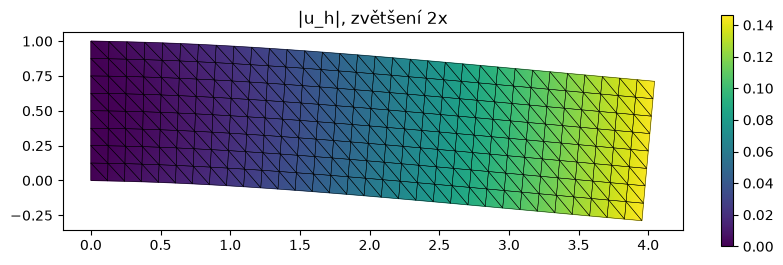

In [27]:
coord, elem, gamma0 = sit_obdelnik(32, 8)                 # P1 síť 32 x 8
u, Kt, bt = vyres(refP1, coord, elem, F, gamma0)
W = 0.5 * u @ Kt @ u                                       # W = 1/2 y^T K y (na Gamma_0 je y~ nulové)
print(f"max |u| = {np.abs(u).max():.4e},  W = {W:.4e},  1/2 b^T y = {0.5 * bt @ u:.4e},  J(y*) = {W - bt @ u:.4e}")

plt.figure(figsize=(10, 3))
plt.colorbar(kresli(coord, elem, u, 3, zvetseni=2))        # deformovaný tvar, barva = |u_h|
plt.show()

**Efektivita.** Úloha s desítkami tisíc neznámých se vyskládá a vyřeší
ve zlomku sekundy.

In [28]:
coord_f, elem_f, gamma0_f = sit_obdelnik(256, 64)          # 32768 trojúhelníků
t = time.perf_counter()
u_f, Kt_f, _ = vyres(refP1, coord_f, elem_f, F, gamma0_f)   # vyskládání i řešení
print(f"{len(elem_f)} prvků, {Kt_f.shape[0]} neznámých, {time.perf_counter() - t:.2f} s")

32768 prvků, 33410 neznámých, 0.28 s


## 11. Výměna prvku: P1 → Q1 (sekce 6.2)

Žádná z funkcí `geometrie`, `matice_tuhosti`, `vektor_sil`, `vyres` nezávisí
na typu prvku. **Změní se jen vstupy:** bazické funkce a kvadratura (obojí
v `refQ1` z části 6) a síť (`ctyruhelniky=True`). Protože $\chi_T$ pro Q1 obecně
není afinní, je $\det J_T$ a gradienty potřeba počítat v každém ze čtyř bodů
zvlášť – a to `einsum` dělá automaticky.

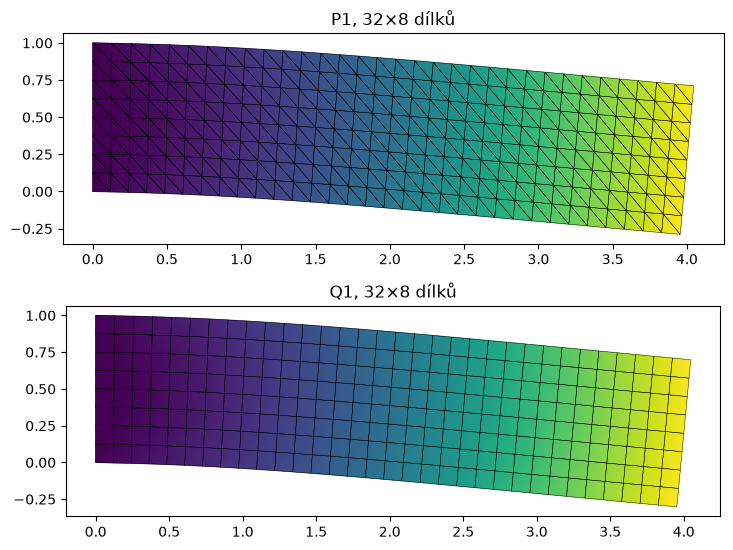

In [29]:
coord_q, elem_q, gamma0_q = sit_obdelnik(32, 8, ctyruhelniky=True)   # Q1 síť 32 x 8
u_q, Kt_q, bt_q = vyres(refQ1, coord_q, elem_q, F, gamma0_q)        # stejná funkce, jiný refQ1

fig, ax = plt.subplots(2, 1, figsize=(10, 5.6))
kresli(coord, elem, u, 3, 2, ax[0])
ax[0].set_title("P1, 32×8 dílků")
kresli(coord_q, elem_q, u_q, 4, 2, ax[1])
ax[1].set_title("Q1, 32×8 dílků")
plt.tight_layout()
plt.show()

**Konvergence.** Na zjemňovaných sítích ($4k\times k$ dílků) sledujeme průhyb
pravého dolního rohu $u_2(4,0)$ a energii $W=\tfrac12\tilde b^\top\tilde y$. Podle
věty 5.2 platí $J(u_h)\to J(u)$ a $\|u-u_h\|_{1,2}\to0$ při $h\to0$
(bez numerické integrace a pro $V_h\subset V$); obě posloupnosti míří ke stejné
hodnotě, Q1 rychleji. Za referenční hodnotu bereme Q1 na síti $k=32$.

 k  neznámých   P1: u2(4,0)       W          Q1: u2(4,0)       W
 1       20   -4.054161e-02  3.676552e-05   -1.040000e-01  8.737500e-05
 2       54   -8.415434e-02  7.150919e-05   -1.344365e-01  1.115088e-04
 4      170   -1.253324e-01  1.045454e-04   -1.470946e-01  1.220865e-04
 8      594   -1.443239e-01  1.200020e-04   -1.509841e-01  1.254421e-04
16     2210   -1.502774e-01  1.249217e-04   -1.520918e-01  1.264248e-04


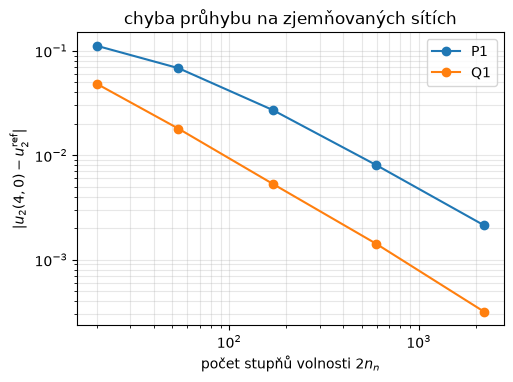

In [30]:
def u2_v_bode(coord, u, x1, x2):
    """Složka u_2 v uzlu se souřadnicemi [x1, x2]."""
    j = np.flatnonzero(np.isclose(coord[:, 0], x1) & np.isclose(coord[:, 1], x2))[0]
    return u[2 * j + 1]


# referenční hodnota: Q1 na síti k = 32 (128 x 32 dílků)
c, e, g0 = sit_obdelnik(128, 32, ctyruhelniky=True)
u_ref = u2_v_bode(c, vyres(refQ1, c, e, F, g0)[0], 4, 0)

vysledky = {"P1": [], "Q1": []}                  # (počet stupňů volnosti, u_2(4,0)) pro graf
print(" k  neznámých   P1: u2(4,0)       W          Q1: u2(4,0)       W")
for k in [1, 2, 4, 8, 16]:
    radek = f"{k:2d}"
    for typ, ref in [("P1", refP1), ("Q1", refQ1)]:
        c, e, g0 = sit_obdelnik(4 * k, k, ctyruhelniky=(typ == "Q1"))   # síť 4k x k
        uk, Kk, bk = vyres(ref, c, e, F, g0)
        vysledky[typ].append((len(bk), u2_v_bode(c, uk, 4, 0)))
        if typ == "P1":
            radek += f"   {len(bk):6d}"
        radek += f"   {vysledky[typ][-1][1]: .6e}  {0.5 * bk @ uk:.6e}"   # u_2(4,0) a W = 1/2 b~^T y~
    print(radek)

graf_konvergence(vysledky, u_ref)                # |u_2(4,0) - u_2^ref| v log-log měřítku

## 12. Deska s otvorem a uzly druhého řádu (sekce 6.1, 6.3)

Síť z Gmsh je jen jiné `coord`, `elem` a jiná množina uzlů na $\Gamma_0$,
výpočetní funkce se nemění. Vezmeme oblast, kterou ručně nezasíťujeme:
obdélník s kruhovým otvorem o poloměru $0.25$ se středem $[2,\,0.5]$. Kruh
není mnohoúhelník, takže síť pokrývá polygonální aproximaci $\Omega_h$ a součet
vah $\sum\omega_{T,q}$ dá plochu $\Omega_h$, nikoli přesně $|\Omega|=4-\pi/16$.
Nejprve síť trojúhelníků, pak čtyřúhelníků; Γ₀ zde určíme jednoduše jako uzly s $x_1=0$.

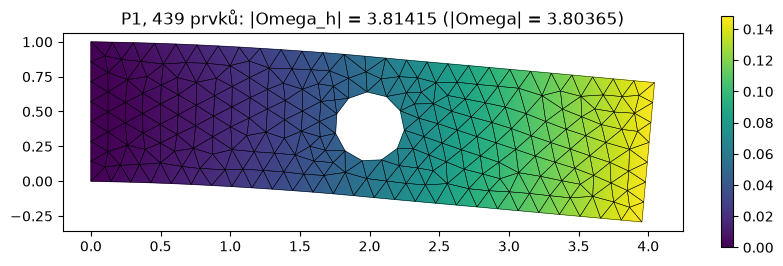

In [31]:
gmsh.clear()

# 1. geometrie: obdélník minus kruh
obdelnik = gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)     # vrátí číslo vytvořené plochy
kruh = gmsh.model.occ.addDisk(2, 0.5, 0, 0.25, 0.25)      # addDisk(střed x, y, z, poloosa a, poloosa b): kruh
# cut(objekty, nástroje): množinový rozdíl obdélník \ kruh; entity se zadávají jako dvojice
# (dimenze, číslo), zde plochy (2, ...). Výsledkem je jediná plocha s otvorem.
gmsh.model.occ.cut([(2, obdelnik)], [(2, kruh)])
gmsh.model.occ.synchronize()                              # předat výslednou geometrii do modelu

# 3. nestrukturovaná trojúhelníková síť s největší délkou hrany prvku 0.15
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.15)
gmsh.model.mesh.generate(2)

# 4. převod; Gamma0 tentokrát jednoduše jako uzly s x1 = 0 (bez fyzikální skupiny)
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord_d = xyz.reshape(-1, 3)[np.argsort(tagy), :2]
_, uzly = gmsh.model.mesh.getElementsByType(2)            # typ 2 = trojúhelník se 3 uzly
elem_d = uzly.reshape(-1, 3).astype(int) - 1
gamma0_d = np.flatnonzero(np.isclose(coord_d[:, 0], 0))

# výpočet je stejný jako na obdélníku; součet vah omega_T,q je plocha Omega_h
u_d, _, _ = vyres(refP1, coord_d, elem_d, F, gamma0_d)
plocha = geometrie(refP1, coord_d, elem_d)[1].sum()

plt.figure(figsize=(10, 3))
plt.colorbar(kresli(coord_d, elem_d, u_d, 3, 2))
plt.title(f"P1, {len(elem_d)} prvků: |Omega_h| = {plocha:.5f} (|Omega| = {4 - np.pi / 16:.5f})")
plt.show()

Čtyřúhelníky: stejný skript, jen v kroku 3 zvolíme algoritmus 8 a spojování
do čtyřúhelníků (`Mesh.RecombineAll`) a v kroku 4 čteme prvky typu 3.

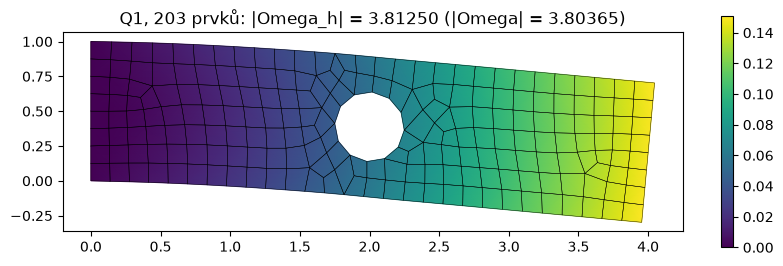

In [32]:
gmsh.clear()

# 1. geometrie: obdélník minus kruh (stejně jako výše)
obdelnik = gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
kruh = gmsh.model.occ.addDisk(2, 0.5, 0, 0.25, 0.25)
gmsh.model.occ.cut([(2, obdelnik)], [(2, kruh)])
gmsh.model.occ.synchronize()

# 3. nestrukturovaná čtyřúhelníková síť
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.15)
# "Mesh.Algorithm" = 8 (Frontal-Delaunay for quads) vytváří trojúhelníky, které se dobře
# párují do pravoúhlých čtyřúhelníků; výchozí algoritmus 6 je určen pro trojúhelníky
gmsh.option.setNumber("Mesh.Algorithm", 8)
# "Mesh.RecombineAll" = 1 spojí trojúhelníky do čtyřúhelníků na všech plochách
# (stejný účinek jako setRecombine pro každou plochu, nemusíme znát číslo plochy po cut)
gmsh.option.setNumber("Mesh.RecombineAll", 1)
gmsh.model.mesh.generate(2)

# 4. převod (typ 3 = čtyřúhelník se 4 uzly)
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord_dq = xyz.reshape(-1, 3)[np.argsort(tagy), :2]
_, uzly = gmsh.model.mesh.getElementsByType(3)
elem_dq = uzly.reshape(-1, 4).astype(int) - 1
gamma0_dq = np.flatnonzero(np.isclose(coord_dq[:, 0], 0))

u_dq, _, _ = vyres(refQ1, coord_dq, elem_dq, F, gamma0_dq)
plocha = geometrie(refQ1, coord_dq, elem_dq)[1].sum()

plt.figure(figsize=(10, 3))
plt.colorbar(kresli(coord_dq, elem_dq, u_dq, 4, 2))
plt.title(f"Q1, {len(elem_dq)} prvků: |Omega_h| = {plocha:.5f} (|Omega| = {4 - np.pi / 16:.5f})")
plt.show()

### Uzly druhého řádu: pozor na pořadí

Gmsh umí vyrobit i sítě s uzly ve středech hran (`setOrder(2)`): šestiuzlové
trojúhelníky a – s volbou `Mesh.SecondOrderIncomplete = 1` – osmiuzlové čtyřúhelníky.
Pro P2 prvek učebního textu je referenční trojúhelník stejný jako pro P1 a uzly jsou

$$\hat N_1=[0,0],\ \hat N_2=[1,0],\ \hat N_3=[0,1],\quad
\hat N_4=[\tfrac12,\tfrac12]\ (\text{hrana }2\text{–}3),\quad
\hat N_5=[0,\tfrac12]\ (\text{hrana }3\text{–}1),\quad
\hat N_6=[\tfrac12,0]\ (\text{hrana }1\text{–}2).$$

**Gmsh čísluje středy hran jinak:** uzel 4 na hraně 1–2, uzel 5 na hraně 2–3,
uzel 6 na hraně 3–1. Přeskládání sloupců `elem[:, [0, 1, 2, 4, 5, 3]]` převede pořadí
Gmsh na pořadí z učebního textu. Osmiuzlový čtyřúhelník Gmsh má středy hran
v pořadí 1–2, 2–3, 3–4, 4–1, stejně jako redukovaný Q2 učebního textu
($\hat N_5=[0,-1]$, $\hat N_6=[1,0]$, $\hat N_7=[0,1]$, $\hat N_8=[-1,0]$).

Na zakřivené hranici Gmsh umístí středový bod přímo na kružnici. Hrana prvku
$\chi_T(\text{hrana})$ je pak parabola procházející vrcholy a středovým bodem
a prvek je „zakřivený trojúhelník“, který kopíruje hranici přesněji než P1.

In [33]:
gmsh.clear()

# 1. geometrie: deska s otvorem
obdelnik = gmsh.model.occ.addRectangle(0, 0, 0, 4, 1)
kruh = gmsh.model.occ.addDisk(2, 0.5, 0, 0.25, 0.25)
gmsh.model.occ.cut([(2, obdelnik)], [(2, kruh)])
gmsh.model.occ.synchronize()

# 3. hrubá trojúhelníková síť; globální volby z předchozí buňky vrátíme na trojúhelníky
gmsh.option.setNumber("Mesh.RecombineAll", 0)             # nespojovat do čtyřúhelníků
gmsh.option.setNumber("Mesh.Algorithm", 6)                # výchozí algoritmus pro trojúhelníky
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.3)
gmsh.model.mesh.generate(2)
# setOrder(2) změní hotovou síť na síť druhého řádu: na každou hranu přidá středový uzel;
# na zakřivené hranici ho umístí přímo na geometrii (na kružnici), ne na úsečku
gmsh.model.mesh.setOrder(2)

# 4. převod: typ 9 = trojúhelník se 6 uzly; sloupce přeskládáme na pořadí učebního textu
_, uzly = gmsh.model.mesh.getElementsByType(9)
P2_gmsh = uzly.reshape(-1, 6).astype(int) - 1
P2_text = P2_gmsh[:, [0, 1, 2, 4, 5, 3]]                  # N_T,1, ..., N_T,6 podle obrázku 6.3
print("P2 prvek 0, pořadí Gmsh:  ", P2_gmsh[0])
print("P2 prvek 0, pořadí textu: ", P2_text[0])
gmsh.finalize()                                           # ukončí Gmsh a uvolní paměť (konec 2D části)

P2 prvek 0, pořadí Gmsh:   [  5  96  64 133 134 135]
P2 prvek 0, pořadí textu:  [  5  96  64 134 135 133]


![pořadí uzlů P2](obrazky_prednaska/16_poradi_P2.png)

## Shrnutí

| Krok | Učební text | Python |
|---|---|---|
| triangulace `coord`, `elem`, $\Gamma_0$ | 6.1, 6.5 | Gmsh + fyzikální skupiny, přečíslování tagů |
| referenční prvek, (6.1) | 6.2 | SymPy: bazické funkce, derivace, kontrola $\delta_{pq}$ |
| kvadratura, `Phi`, `dPhi` | 6.4 | předem spočtená pole |
| $J_T$, $\det J_T>0$, (6.7), (6.9) | 6.3, 6.4 | jeden `einsum` pro všechny prvky |
| $\tilde K=B^\top D_{\rm elast}B$ | 6.7 | řídké matice, `kron` |
| $\tilde b$ | 6.8 | `einsum` + `bincount` |
| $I_D$, $Ky=b$ | 6.6, 5 | výběr indexů, `spsolve` |

Kontroly, které se vyplatí dělat vždy: (6.1), $\det J_T>0$ (číslování!),
součet vah = plocha, symetrie $\tilde K$ a tři nulová vlastní čísla (tuhé posuny a otočení), součet sil,
konvergence při zjemňování. **Pořadí uzlů v `elem` musí odpovídat
referenčnímu prvku** – i u sítí z Gmsh.

Hotový kód z této hodiny je v souboru `mkp2d.py` (včetně převodu sítě `z_gmsh`).

## 13. Bonus: sítě ve 3D

Gmsh pracuje stejně i ve 3D: geometrie je objem, `generate(3)` vytvoří
čtyřstěny a s předepsanými počty uzlů (`transfinite`) a spojováním šestistěny.
Výsledkem je opět `coord` (nyní se třemi souřadnicemi) a `elem`.
Referenční prvky a kvadratury se zobecní přímočaře:

* **P1 čtyřstěn:** $\hat T$ s vrcholy $\hat N_1=[0,0,0]$, $\hat N_2=[1,0,0]$, $\hat N_3=[0,1,0]$, $\hat N_4=[0,0,1]$,
  $$\hat\varphi_1=1-\xi_1-\xi_2-\xi_3,\quad\hat\varphi_2=\xi_1,\quad\hat\varphi_3=\xi_2,\quad\hat\varphi_4=\xi_3,$$
  kvadratura: jeden bod v těžišti $[\tfrac14,\tfrac14,\tfrac14]$ s vahou $\tfrac16$ (objem $\hat T$);
* **Q1 šestistěn:** $\hat T=(-1,1)^3$ s vrcholy $\hat N_p=[\hat\xi_{p,1},\hat\xi_{p,2},\hat\xi_{p,3}]$
  (spodní stěna $\xi_3=-1$ proti směru hodinových ručiček, pak horní stěna, jako v Gmsh),
  $$\hat\varphi_p=\tfrac18(1+\xi_1\hat\xi_{p,1})(1+\xi_2\hat\xi_{p,2})(1+\xi_3\hat\xi_{p,3}),$$
  kvadratura: $2\times2\times2$ Gaussových bodů $[\pm\tfrac1{\sqrt3},\pm\tfrac1{\sqrt3},\pm\tfrac1{\sqrt3}]$ s vahami $1$.

Funkce `referencni_prvek` a `geometrie` fungují beze změny i ve 3D (`einsum`
i determinant nejsou vázané na dimenzi): $J_T$ je matice $3\times3$ a součet vah
$\sum\omega_{T,q}$ dává objem. Vyskládání matice tuhosti ve 3D je náplní úloh 5 a 6.

In [34]:
gmsh.initialize()                                         # Gmsh jsme ukončili, spustíme ho znovu
gmsh.option.setNumber("General.Terminal", 0)              # bez výpisů do konzole

# P1 čtyřstěn: phi^ = (1 - xi_1 - xi_2 - xi_3, xi_1, xi_2, xi_3), bod [1/4, 1/4, 1/4] s vahou 1/6
ref_tetra = referencni_prvek([1 - xi1 - xi2 - xi3, xi1, xi2, xi3],
                             [(0, 0, 0), (1, 0, 0), (0, 1, 0), (0, 0, 1)],
                             [(1 / 4, 1 / 4, 1 / 4)], [1 / 6])
# Q1 šestistěn: vrcholy v pořadí Gmsh, phi^_p = 1/8 (1 + xi_1 a)(1 + xi_2 b)(1 + xi_3 c), 2 x 2 x 2 Gaussových bodů
uzly_hexa = [(-1, -1, -1), (1, -1, -1), (1, 1, -1), (-1, 1, -1),
             (-1, -1, 1), (1, -1, 1), (1, 1, 1), (-1, 1, 1)]
ref_hexa = referencni_prvek(
    [(1 + xi1 * a) * (1 + xi2 * b) * (1 + xi3 * c) / 8 for a, b, c in uzly_hexa], uzly_hexa,
    [(a * g, b * g, c * g) for a, b, c in uzly_hexa], [1] * 8)

**Čtyřstěny: válec ze sekce 3.2** s poloměrem $R=0.5$ a výškou $\ell=2$,
tj. $\Omega=\{x\in\mathbb R^3\mid x_1^2+x_2^2<R^2,\ 0<x_3<\ell\}$.
Plášť válce je nahrazen rovinnými stěnami, a proto je objem $\Omega_h$
o něco menší než $\pi R^2\ell$.

In [35]:
R, ell = 0.5, 2.0
gmsh.clear()

# 1. geometrie: addCylinder(x, y, z střed podstavy, dx, dy, dz osa, poloměr) -> objem 1
gmsh.model.occ.addCylinder(0, 0, 0, 0, 0, ell, R)
gmsh.model.occ.synchronize()

# 3. nestrukturovaná síť; generate(3) postupně zasíťuje hrany, stěny (trojúhelníky)
#    a nakonec objem (čtyřstěny)
gmsh.option.setNumber("Mesh.MeshSizeMax", 0.2)
gmsh.model.mesh.generate(3)

# 4. převod: ve 3D ponecháme všechny tři souřadnice; typ 4 = čtyřstěn se 4 uzly
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coord3 = xyz.reshape(-1, 3)[np.argsort(tagy)]
_, uzly = gmsh.model.mesh.getElementsByType(4)
tetra = uzly.reshape(-1, 4).astype(int) - 1

_, w3 = geometrie(ref_tetra, coord3, tetra)                # stejná funkce jako ve 2D
print(f"{len(tetra)} čtyřstěnů, |Omega_h| = {w3.sum():.4f}, pi R^2 l = {np.pi * R ** 2 * ell:.4f}")

1099 čtyřstěnů, |Omega_h| = 1.5398, pi R^2 l = 1.5708


![válec](obrazky_prednaska/17_valec_ctyrsteny.png)

**Šestistěny: hranol $(0,4)\times(0,1)\times(0,1)$ z úloh 5 a 6.** Na všech hranách
předepíšeme počet uzlů, všechny stěny i objem označíme jako strukturované
a stěny spojíme do čtyřúhelníků.

In [36]:
gmsh.clear()

# 1. geometrie: addBox(x, y, z roh, dx, dy, dz) = hranol (0,4) x (0,1) x (0,1), objem 1
gmsh.model.occ.addBox(0, 0, 0, 4, 1, 1)
gmsh.model.occ.synchronize()

# 3. strukturovaná šestistěnová síť:
# getEntities(1) vrátí všechny hrany jako dvojice (1, číslo); getMass(1, hrana) je délka hrany.
# Každá hrana dostane délka / 0.25 + 1 uzlů, tj. dílky délky 0.25.
for _, hrana in gmsh.model.getEntities(1):
    delka = gmsh.model.occ.getMass(1, hrana)
    gmsh.model.mesh.setTransfiniteCurve(hrana, round(delka / 0.25) + 1)
# všech šest stěn: pravidelná mřížka a spojení trojúhelníků do čtyřúhelníků
for _, stena in gmsh.model.getEntities(2):
    gmsh.model.mesh.setTransfiniteSurface(stena)
    gmsh.model.mesh.setRecombine(2, stena)
# setTransfiniteVolume: pravidelná mřížka uvnitř objemu 1; se čtyřúhelníkovými stěnami
# z ní vzniknou šestistěny (kvádry)
gmsh.model.mesh.setTransfiniteVolume(1)
gmsh.model.mesh.generate(3)

# 4. převod: typ 5 = šestistěn s 8 uzly
tagy, xyz, _ = gmsh.model.mesh.getNodes()
coordH = xyz.reshape(-1, 3)[np.argsort(tagy)]
_, uzly = gmsh.model.mesh.getElementsByType(5)
hexa = uzly.reshape(-1, 8).astype(int) - 1

_, wH = geometrie(ref_hexa, coordH, hexa)
detJ_H = np.linalg.det(np.einsum("epi,qpj->eqij", coordH[hexa], ref_hexa["dPhi"]))
print(f"{len(hexa)} šestistěnů, |Omega_h| = {wH.sum():.4f} (přesně 4), min det J_T = {detJ_H.min():.4f} > 0")
gmsh.finalize()

256 šestistěnů, |Omega_h| = 4.0000 (přesně 4), min det J_T = 0.0020 > 0


![hranol](obrazky_prednaska/18_hranol_sestisteny.png)